## Load Sample from ROAMM Dataset

Loading single subject from ROAMM Data set

In [12]:
import os
import pickle as pkl

import numpy as np


single_subject = pkl.load(open(os.path.join("Data","ROAMM", "sub-10014","sub-10014_task-ReMind_run-01_mldata.pkl"), "rb"))
single_subject



,Fp1,AF7,AF3,F1,F3,F5,F7,FT7,FC5,FC3,...,LPupil,RX,RY,RPupil,blink_interp_LX,blink_interp_LY,blink_interp_LPupil,blink_interp_RX,blink_interp_RY,blink_interp_RPupil
0,1.003871e-05,-0.000009,-1.296942e-06,-1.143055e-07,-0.000009,-8.435023e-06,-1.414173e-05,-0.000009,-0.000009,-2.477431e-06,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1.331890e-05,-0.000005,-1.211723e-06,-1.628259e-06,-0.000010,-8.102186e-06,-1.334838e-05,-0.000009,-0.000009,-2.405989e-06,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1.495398e-05,-0.000003,-6.835898e-07,-2.152282e-06,-0.000009,-6.108416e-06,-9.549383e-06,-0.000007,-0.000007,-1.101047e-06,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1.314708e-05,-0.000005,-9.610865e-07,-2.243665e-06,-0.000008,-4.909185e-06,-7.040125e-06,-0.000005,-0.000005,1.571541e-07,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,8.926854e-06,-0.000010,-2.379462e-06,-2.803911e-06,-0.000008,-6.189222e-06,-8.904932e-06,-0.000006,-0.000005,1.974937e-07,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
168699,5.700471e-06,-0.000011,3.198152e-06,6.128639e-06,-0.000003,-6.749503e-06,-1.670166e-05,-0.000009,-0.000006,-9.754613e-07,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
168700,1.150247e-06,-0.000011,-3.218826e-07,2.489532e-06,-0.000005,-7.274736e-06,-1.524394e-05,-0.000006,-0.000005,-1.666173e-06,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
168701,-2.843191e-06,-0.000011,-2.878874e-06,-4.959059e-07,-0.000006,-6.333159e-06,-1.143184e-05,-0.000002,-0.000002,-1.731910e-06,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
168702,-3.463220e-06,-0.000011,-3.264210e-06,-1.535063e-06,-0.000006,-3.575349e-06,-5.994205e-06,0.000003,0.000001,-7.080676e-07,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


List All Columns in this dataset

In [3]:
list(single_subject.keys())

['Fp1',
 'AF7',
 'AF3',
 'F1',
 'F3',
 'F5',
 'F7',
 'FT7',
 'FC5',
 'FC3',
 'FC1',
 'C1',
 'C3',
 'C5',
 'T7',
 'TP7',
 'CP5',
 'CP3',
 'CP1',
 'P1',
 'P3',
 'P5',
 'P7',
 'P9',
 'PO7',
 'PO3',
 'O1',
 'Iz',
 'Oz',
 'POz',
 'Pz',
 'CPz',
 'Fpz',
 'Fp2',
 'AF8',
 'AF4',
 'Afz',
 'Fz',
 'F2',
 'F4',
 'F6',
 'F8',
 'FT8',
 'FC6',
 'FC4',
 'FC2',
 'FCz',
 'Cz',
 'C2',
 'C4',
 'C6',
 'T8',
 'TP8',
 'CP6',
 'CP4',
 'CP2',
 'P2',
 'P4',
 'P6',
 'P8',
 'P10',
 'PO8',
 'PO4',
 'O2',
 'time',
 'sfreq',
 'first_pass_reading',
 'page_num',
 'page_start',
 'page_end',
 'page_dur',
 'is_mw',
 'mw_onset',
 'mw_offset',
 'mw_dur',
 'run_num',
 'story_name',
 'is_fix',
 'fix_L_eye',
 'fix_L_tStart',
 'fix_L_tEnd',
 'fix_L_duration',
 'fix_L_xAvg',
 'fix_L_yAvg',
 'fix_L_pupilAvg',
 'fix_L_fixed_word',
 'fix_L_fixed_word_key',
 'fix_R_eye',
 'fix_R_tStart',
 'fix_R_tEnd',
 'fix_R_duration',
 'fix_R_xAvg',
 'fix_R_yAvg',
 'fix_R_pupilAvg',
 'fix_R_fixed_word',
 'fix_R_fixed_word_key',
 'is_blink',
 'bli

### For this subject check Mind Wandering Events

We aggregate the Onsets and Offsets of MW events getting:
1. Mind Wandering Duration
2. Fixation number and Mean Fixation Duration during the episode
3. Saccade number and Mean Saccade Duration during the episode
4. Blink Count and duration (divided by 2 because we have 2 eyes)
5. Words that participant has been fixating on during the episodes
6. Page number of the story (as a proxy for time-on-task)


In [4]:

result = (
    single_subject.groupby(['mw_onset', 'mw_offset'])
      .agg(
          MW_Duration=('time', lambda x: x.count() / 256),
          fix_R_duration=('fix_R_duration', 'mean'),
          fix_N=('is_fix',  lambda x: ((x == 1) & (x.shift() != 1)).sum()),
          Sacc_N=('is_sacc', lambda x: ((x == 1) & (x.shift() != 1)).sum()),
          Sacc_R_duration=('sacc_R_duration', 'mean'),
          blink_count=('is_blink',lambda x: ((x == 1) & (x.shift() != 1)).sum()/2),
          blink_duration=('blink_R_duration', 'mean'),

          fixed_Words=('fix_R_fixed_word', lambda x: x.dropna().unique().tolist()),

          page_num=('page_num', 'mean'),
      )
      .reset_index()
)

result

,mw_onset,mw_offset,MW_Duration,fix_R_duration,fix_N,Sacc_N,Sacc_R_duration,blink_count,blink_duration,fixed_Words,page_num
0,18.726262,20.056262,1.332031,203.803333,7,6,26.833333,0.0,NaN,"[first, Kuiper, object, was]",0.0
1,100.657262,102.723263,2.066406,212.780761,10,9,47.662338,0.0,NaN,"[Urbain, Verrier, and, mechanics, predict, its...",1.0
2,129.382262,131.518262,2.136719,335.164583,7,8,54.111111,0.0,NaN,"[in, wealthy, started, Bostonian, had, project...",2.0
3,203.653263,207.966262,4.312500,221.946597,18,18,39.126761,0.0,NaN,"[Tombaugh, urged, Slipher, suggest, name, the,...",3.0
4,252.015262,252.882262,0.867188,201.380208,4,5,27.392857,0.0,NaN,"[unpopular, name, announced, 1]",4.0
5,276.795262,288.080263,11.285156,213.203472,43,43,811.350126,1.0,1355.140000,"[Buddhist, indigenous, Pluto,, mythology., sug...",5.0
6,327.191263,330.926263,3.738281,617.600912,10,10,41.934211,0.0,NaN,"[recalculate, could, therefore, more, percent,...",6.0
7,387.020263,403.320263,16.296875,246.285004,65,66,45.527237,0.0,NaN,"[from, questioning, population., omitting, Plu...",7.0
8,444.059263,452.096263,8.035156,322.768194,25,25,859.507143,0.5,1252.000000,"[which, the, official, definition, term, ""plan...",8.0
9,492.926263,504.675263,11.746094,202.654028,46,44,316.442263,4.0,459.681818,"[all, share, of, new, stinks,, Moon,, be, woul...",9.0


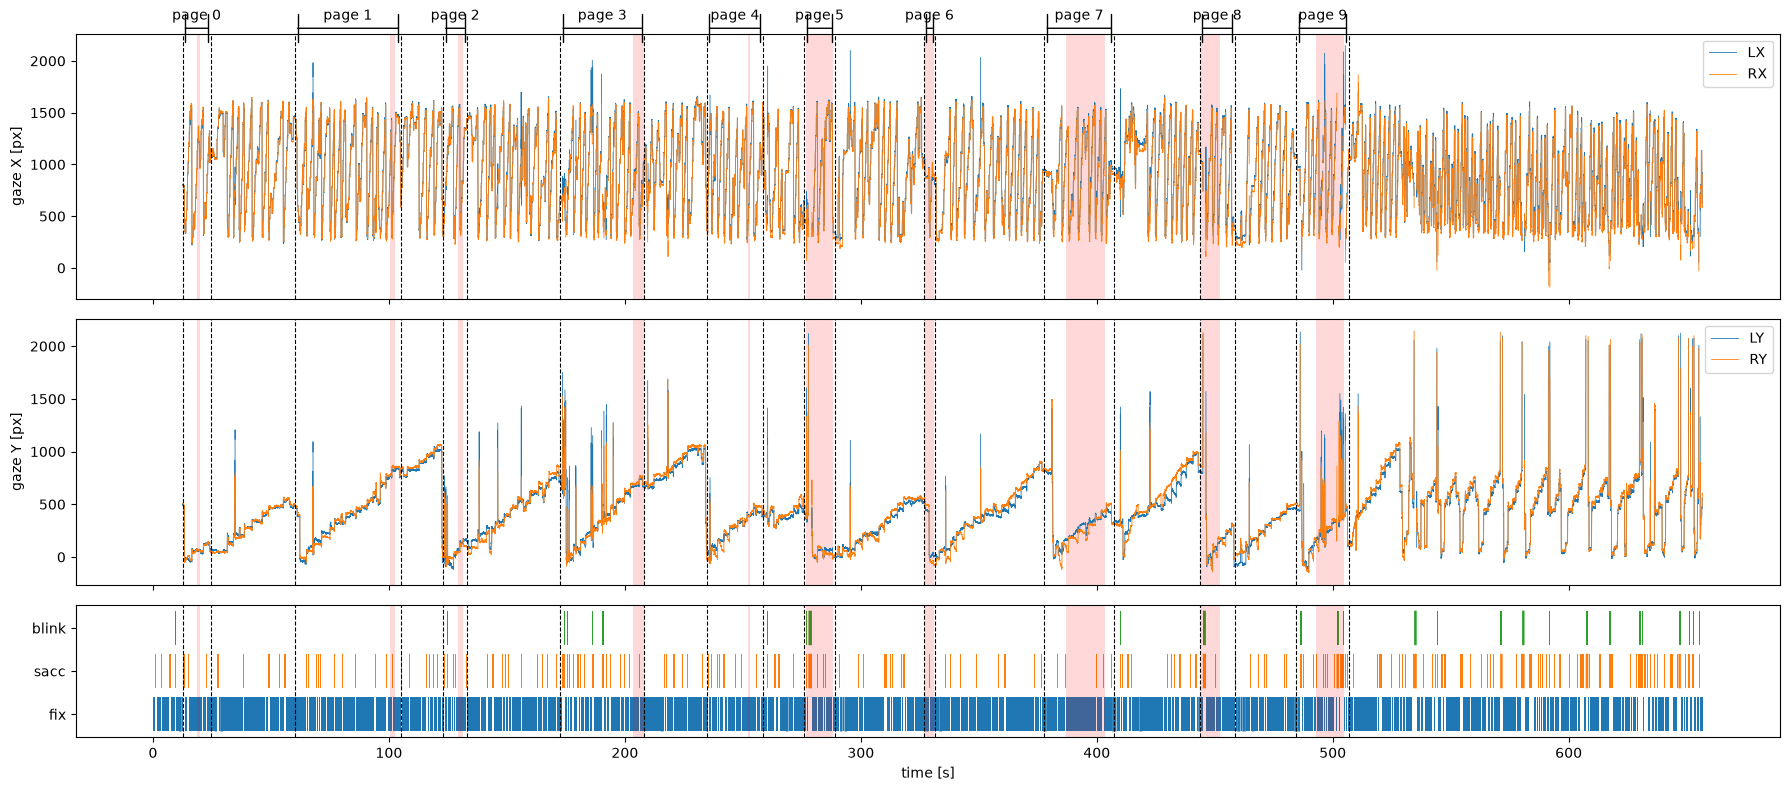

In [11]:
import matplotlib.pyplot as plt

def plot_full(df):
    t = df['time']
    fig, (ax_x, ax_y, ax_e) = plt.subplots(3, 1, figsize=(18, 8), sharex=True,
                                           gridspec_kw={'height_ratios': [2, 2, 1]})
    for ax, c in ((ax_x, 'X'), (ax_y, 'Y')):
        ax.plot(t, df[f'L{c}'], lw=0.6, label=f'L{c}')
        ax.plot(t, df[f'R{c}'], lw=0.6, label=f'R{c}')
        ax.set_ylabel(f'gaze {c} [px]'); ax.legend(loc='upper right')
    for i, ev in enumerate(['is_fix', 'is_sacc', 'is_blink']):
        ax_e.fill_between(t, i, i + 0.8, where=df[ev] == 1, step='mid', lw=0)
    ax_e.set_yticks([0.4, 1.4, 2.4], ['fix', 'sacc', 'blink']); ax_e.set_xlabel('time [s]')

    # MW -> shade na każdym panelu
    for on, off in df[['mw_onset', 'mw_offset']].dropna().drop_duplicates().values:
        for ax in (ax_x, ax_y, ax_e):
            ax.axvspan(on, off, color='red', alpha=0.15, lw=0)

    # Strony -> przerywane linie + klamra |---| z podpisem nad górnym panelem
    pages = df[['page_num', 'page_start', 'page_end']].dropna().drop_duplicates('page_num')
    for p, start, end in pages.values:
        for ax in (ax_x, ax_y, ax_e):
            ax.axvline(start, color='k', ls='--', lw=0.8)
            ax.axvline(end, color='k', ls='--', lw=0.8)
        ax_x.annotate('', xy=(start, 1.02), xytext=(end, 1.02), xycoords=('data', 'axes fraction'),
                      arrowprops=dict(arrowstyle='|-|', lw=1))
        ax_x.text((start + end) / 2, 1.04, f'page {int(p)}', ha='center', va='bottom',
                  transform=ax_x.get_xaxis_transform())

    plt.tight_layout(); plt.show()

plot_full(single_subject)